# Notebook to look at flybratron data from mosquitoes

## Imports

In [115]:
import os
import h5py
import pyabf

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib as mpl

from mosquito.util import idx_by_thresh

## Helper functions

In [116]:
def my_load_abf(filename, print_flag=False):
    """
    Helper function to load ABF file (containing signals from Digidata) and put
    out a dictionary with useful info.

    Args:
        filename: full path to ABF file
        print_flag: bool, print header info upon loading?

    Returns: abf_dict, a dict containing abf data and info
    """
    # load abf object
    abf = pyabf.ABF(filename)

    # create dict to store abf info
    abf_dict = dict()

    # grab info from abf
    abf_dict['sampling_freq'] = abf.sampleRate  # sampling frequency
    abf_dict['filepath'] = abf.abfFilePath
    abf_dict['units'] = abf.adcUnits
    abf_dict['header'] = abf.headerText

    channel_names = abf.adcNames

    # grab channel data
    for ith, name in enumerate(channel_names):
        # set channel
        abf.setSweep(sweepNumber=0, channel=ith)

        # get time once
        if ith == 0:
            abf_dict['time'] = abf.sweepX

        # get current channel data
        abf_dict[name] = abf.sweepY

    # if we have multiple emg signals, put those in a list under a single key
    emg_keys = [key for key in abf_dict.keys() if 'emg' in key]
    if len(emg_keys) > 1:
        # group into list and put under 'emg' key
        emg_list = [abf_dict[kkey] for kkey in emg_keys]
        abf_dict['emg'] = emg_list

        # remove other entries
        remove_keys = [k for k in emg_keys if not k=='emg']
        for rm_key in remove_keys:
            del abf_dict[rm_key]

    # print header info?
    if print_flag:
        print(abf_dict['header'])

    return abf_dict

In [117]:
def my_zscore(x):
    """
    Convenience function for z scoring
    """
    return (x - np.nanmean(x))/np.nanstd(x)
    

In [118]:
def volts_to_index(v_step=0.2, v_offset=2.5):
    """ 
    Returns a fuction for converting a voltage to index based on the given
    step and offset parametes.  
    f"""
    def volts_to_index_func(volts):
        return (volts - v_offset)/v_step
    return volts_to_index_func

In [119]:
def get_amp_trial_index(abf_dict, n_reps=6):
    """
    Quick and dirty function to get the indices of each amplitude of flybratron stimulation from the full time series. Used to group data by trial type

    Needs cleaning up!
    
    """
    # convert from volts to index
    v2i_func = volts_to_index()
    index_code = v2i_func(abf_dict['V Code']) 
    index_vals = np.unique(np.round(index_code))

    # or each voltage/index value, get a list. the list contains data array indices where the voltage/index value is obtained in the full time series
    idx_list = []
    for val in index_vals:
        # print(val)
        idx = (np.round(index_code) == val)
        if np.sum(idx) > 1:
            idx_l = idx_by_thresh(idx)
        else:
            idx_l = []
        idx_list.append(idx_l)

    # find index_vals for which we have 'n_reps' entries. 
    # NB: for now, there should be 14 of them for an amplitude sweep because we test 7 amplitude values over 2 directions
    idx_lengths = [len(idx_l) for idx_l in idx_list]
    amp_index_vals = [index_vals[ith] for ith in range(len(idx_lengths)) if idx_lengths[ith]==n_reps]
    amp_idx_lists = [idx_list[ith] for ith in range(len(idx_lengths)) if idx_lengths[ith]==n_reps]

    # return
    return amp_index_vals, amp_idx_lists
    

In [120]:
def quick_plot_var_by_amp(abf_dict, data_name='HA Kinefl', n_reps=6, amp_vals=[200,400,600,800,1000,1200,1600], colormap_name='PuOr'):
    """
    Quick and dirty function to make plots of flybratron data from amplitude sweeps grouped by amplitude. To aid in data exploration

    ***NB: not sure that legend is correct -- need to update with accurate trial structure info ***
    
    """
    # get indices for each amplitude value using our other helper function
    amp_idx_vals, amp_idx_lists = get_amp_trial_index(abf_dict, n_reps=n_reps)

    # get minimum length for all trial data periods (we need this so the indices of everything match)
    # NB: this is probably just an issue with idx_by_thresh !!! 
    idx_len = 1e8
    
    for idx_l in amp_idx_lists:
        for idx in idx_l:
            if len(idx) < idx_len:
                idx_len = len(idx)

    # initialize plot
    fig, ax = plt.subplots()

    # get kinematic data 
    data_array = abf_dict[data_name]  # can switch to wing or whatever
    
    # make sure we're getting both negative and positive amp vals
    amp_vals_full = sorted([-1*val for val in amp_vals] + amp_vals)
    colors = mpl.colormaps[colormap_name].resampled(len(amp_idx_vals))
    color_idx = np.linspace(0, 1, len(amp_idx_vals))

    # get time range to plot over
    time = abf_dict['time'][:idx_len]
    
    # loop over data trials
    for ith in range(len(amp_idx_vals)):
        # get data for current amplitude type
        idx_l = amp_idx_lists[ith]
        dat = np.vstack([data_array[idx][:idx_len] for idx in idx_l])
        ax.plot(time, np.mean(dat, axis=0), color=colors(color_idx[ith]), label=amp_vals_full[ith])
    
    ax.set_xlabel('time (s?)')
    ax.set_ylabel(data_name)
    ax.set_title(data_name)
    ax.legend(ncols=2, fontsize='x-small')

    return fig, ax

## Load data

In [121]:
# path to data
data_path = r'C:\Users\samcw\Dropbox\flybratron\data\01_20251014\abf'
sorted(os.listdir(data_path))

['flyguycooldata_0000.abf',
 'flyguycooldata_0001.abf',
 'flyguycooldata_0007.abf',
 'flyguycooldata_0008.abf',
 'flyguycooldata_0010.abf',
 'flyguycooldata_0011.abf',
 'flyguycooldata_0012.abf',
 'flyguycooldata_0013.abf',
 'flyguycooldata_0014.abf',
 'flyguycooldata_0017.abf',
 'flyguycooldata_0018.abf',
 'flyguycooldata_0019.abf']

In [122]:
data_fn = 'flyguycooldata_0019.abf'

In [123]:
# read data 
data_path_full = os.path.join(data_path, data_fn)
abf_dict = my_load_abf(data_path_full)

In [124]:
abf_dict.keys()

dict_keys(['sampling_freq', 'filepath', 'units', 'header', 'time', 'L WBA', 'R WBA', 'L m R WBA', 'Frequency', 'Accel', 'Ephys', 'L Kinefly', 'R Kinefly', 'V Code', 'HA Kinefl'])

Text(0.5, 1.0, 'Wingbeat analyzer')

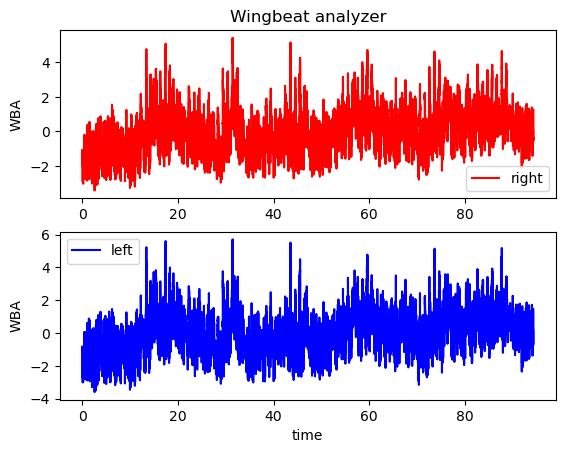

In [125]:
# plot wingbeat analyzer to check
fig, (ax1, ax2) = plt.subplots(2,1)

ax1.plot(abf_dict['time'], my_zscore(abf_dict['R WBA']), 'r-', label='right')
ax2.plot(abf_dict['time'], my_zscore(abf_dict['L WBA']), 'b-', label='left')

ax2.set_xlabel('time')
ax1.set_ylabel('WBA')
ax2.set_ylabel('WBA')
ax1.legend()
ax2.legend()

ax1.set_title('Wingbeat analyzer')

Text(0.5, 1.0, 'Kinefly')

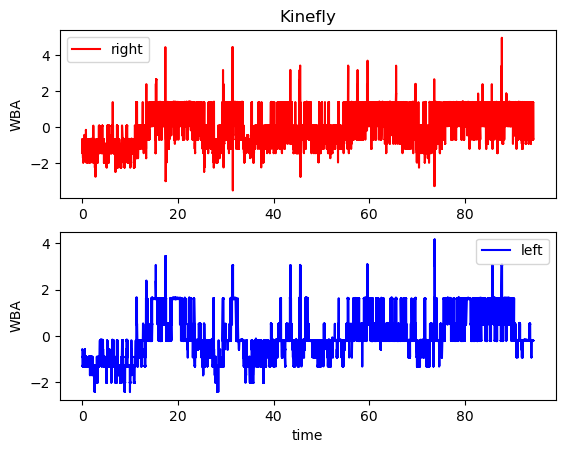

In [126]:
# plot to check
fig, (ax1, ax2) = plt.subplots(2,1)

ax1.plot(abf_dict['time'], my_zscore(abf_dict['R Kinefly']), 'r-', label='right')
ax2.plot(abf_dict['time'], my_zscore(abf_dict['L Kinefly']), 'b-', label='left')

ax2.set_xlabel('time')
ax1.set_ylabel('WBA')
ax2.set_ylabel('WBA')
ax1.legend()
ax2.legend()

ax1.set_title('Kinefly')

Text(0.5, 1.0, 'Head angle and voltage code')

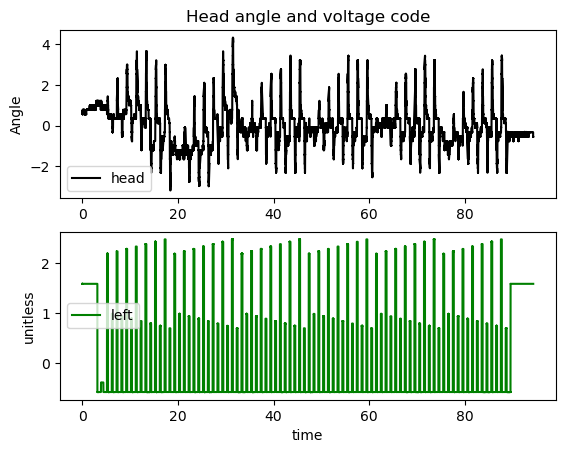

In [127]:
# also look at head angles
fig, (ax1, ax2) = plt.subplots(2,1)

ax1.plot(abf_dict['time'], my_zscore(abf_dict['HA Kinefl']), 'k-', label='head')
ax2.plot(abf_dict['time'], my_zscore(abf_dict['V Code']), 'g-', label='left')

ax2.set_xlabel('time')
ax1.set_ylabel('Angle')
ax2.set_ylabel('unitless')
ax1.legend()
ax2.legend()

ax1.set_title('Head angle and voltage code')

## Examine data grouped by amplitude

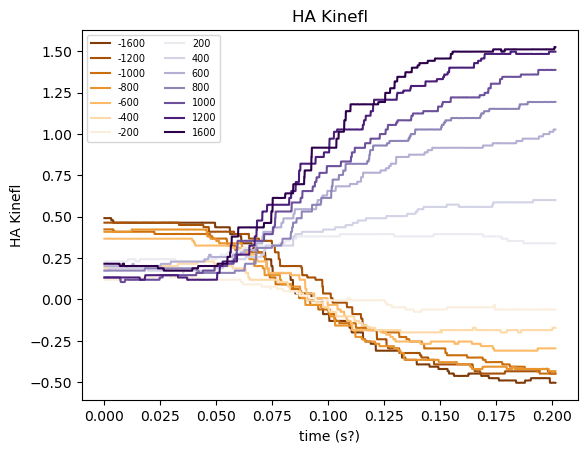

In [128]:
# head angle
fig, ax = quick_plot_var_by_amp(abf_dict, data_name='HA Kinefl', n_reps=6)

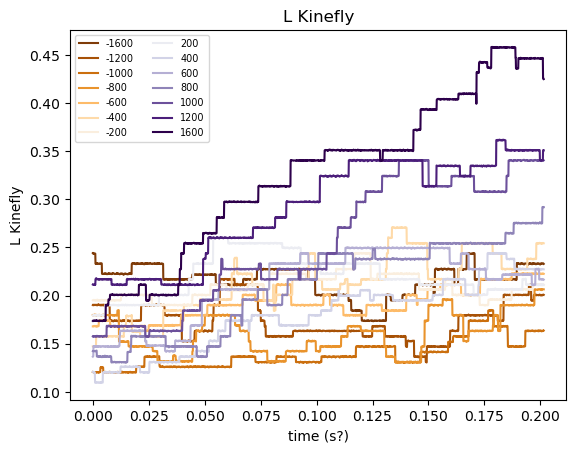

In [129]:
# left wing KINEFLY
fig, ax = quick_plot_var_by_amp(abf_dict, data_name='L Kinefly')

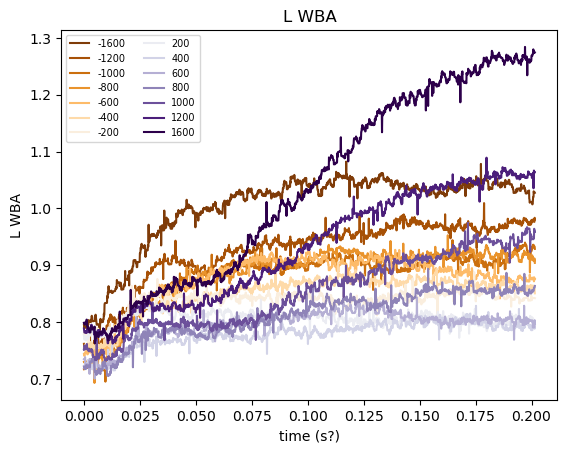

In [130]:
# left wing WBA
fig, ax = quick_plot_var_by_amp(abf_dict, data_name='L WBA')

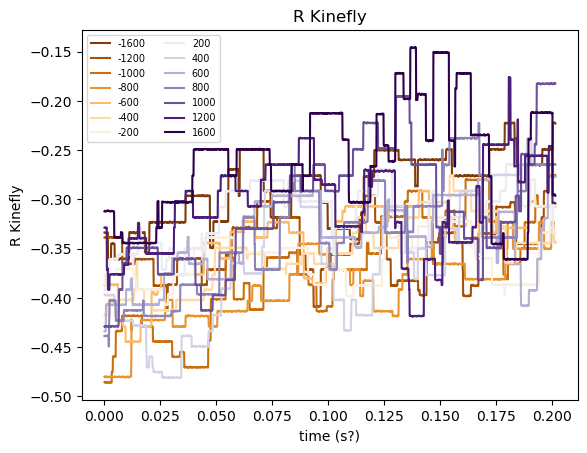

In [131]:
# right wing KINEFLY
fig, ax = quick_plot_var_by_amp(abf_dict, data_name='R Kinefly')

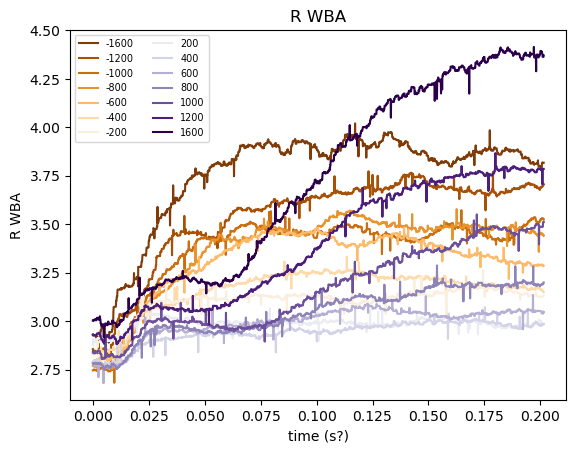

In [132]:
# right wing WBA
fig, ax = quick_plot_var_by_amp(abf_dict, data_name='R WBA')

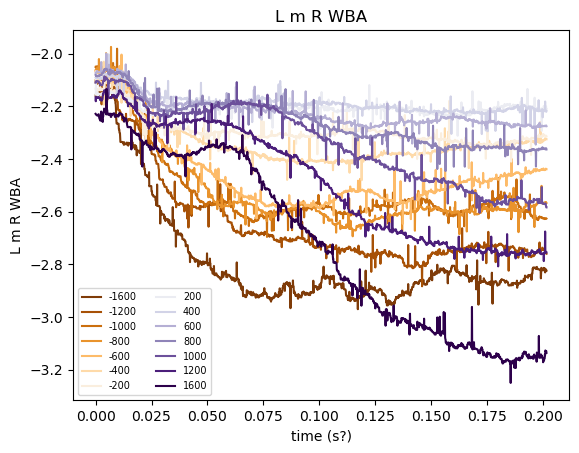

In [133]:
# left minus right
fig, ax = quick_plot_var_by_amp(abf_dict, data_name='L m R WBA')


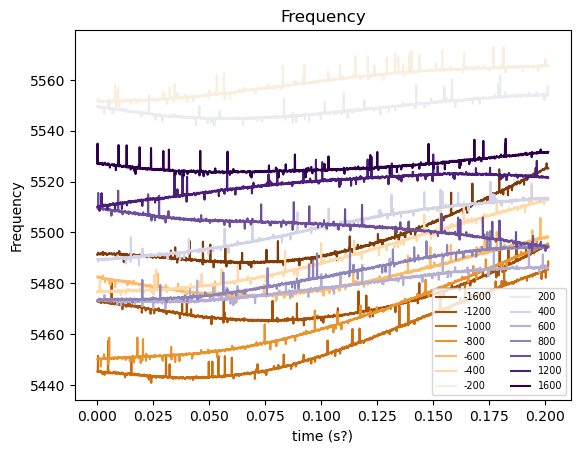

In [134]:
# WBF
fig, ax = quick_plot_var_by_amp(abf_dict, data_name='Frequency')

## Scratch

In [135]:
# get voltage code
n_vals = 21  # will change depending on trial type
v2i_func = volts_to_index()
index_code = v2i_func(abf_dict['V Code']) 
index_vals = np.unique(np.round(index_code))

# v_code_vals = np.digitize(abf_dict['V Code'], bins=

In [136]:
# loop over index values
idx_list = []
for val in index_vals:
    # print(val)
    idx = (np.round(index_code) == val)
    if np.sum(idx) > 1:
        idx_l = idx_by_thresh(idx)
    else:
        idx_l = []
    idx_list.append(idx_l)

In [137]:
# find index_vals for which we have 6 entries. 
# There should be 14 of them for an amplitude sweep because we test 7 amplitude values over 2 directions
idx_lengths = [len(idx_l) for idx_l in idx_list]
idx_lengths.count(6)
amp_index_vals = [index_vals[ith] for ith in range(len(idx_lengths)) if idx_lengths[ith]==6]
amp_idx_lists = [idx_list[ith] for ith in range(len(idx_lengths)) if idx_lengths[ith]==6]


In [138]:
# get minimum length for all trial data periods (we need this so the indices of everything match)
""" NB: this is probably just an issue with idx_by_thresh !!! """
idx_len = 10000

for idx_l in amp_idx_lists:
    for idx in idx_l:
        if len(idx) < idx_len:
            idx_len = len(idx)

print(idx_len)
    
# dat = np.vstack([data_array[idx] for idx in idx_l])

2016


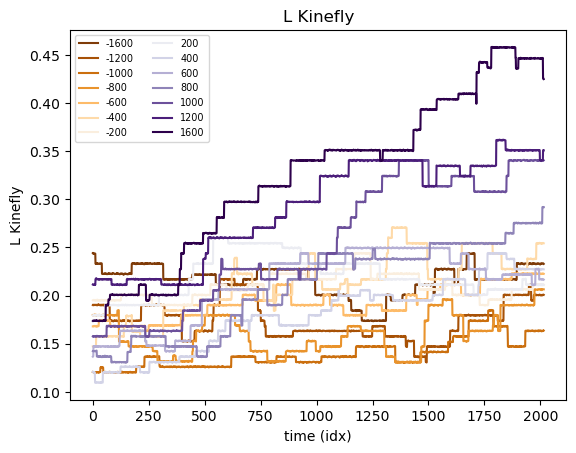

In [139]:
# loop over amplitude values
fig, ax = plt.subplots()

# which kinematic data should we use
data_name = 'L Kinefly'  # 'HA Kinefl', 'L m R WBA', 'Frequency', 'L Kinefly'
data_array = abf_dict[data_name]  # can switch to wing or whatever

# i guess just hard-code in amp values?
amp_vals = [-1600, -1200, -1000, -800, -600, -400, -200, 200, 400, 600, 800, 1000, 1200, 1600]
# colors
colors = mpl.colormaps['PuOr'].resampled(len(amp_index_vals))
color_idx = np.linspace(0, 1, len(amp_index_vals))

# loop over data trials
for ith in range(len(amp_index_vals)):
    # get data for current amplitude type
    idx_l = amp_idx_lists[ith]
    dat = np.vstack([data_array[idx][:idx_len] for idx in idx_l])
    ax.plot(np.mean(dat, axis=0), color=colors(color_idx[ith]), label=amp_vals[ith])

ax.set_xlabel('time (idx)')
ax.set_ylabel(data_name)
ax.set_title(data_name)
ax.legend(ncols=2, fontsize='x-small')